In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report
import pickle




In [2]:

df = pd.read_csv("reviews.csv")


In [3]:

df = df[['content', 'score']]


In [4]:

df.dropna(inplace=True)

In [5]:

def convert_sentiment(score):
    if score >= 4:
        return "Positive"
    elif score == 3:
        return "Neutral"
    else:
        return "Negative"

df['sentiment'] = df['score'].apply(convert_sentiment)



In [6]:
# Preprocess text
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)  # Remove special characters
    tokens = word_tokenize(text)
    tokens = [word for word in tokens if word not in stopwords.words('english')]
    return ' '.join(tokens)

nltk.download('punkt')
nltk.download('stopwords')
df['cleaned_content'] = df['content'].apply(clean_text)



[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\alex\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\alex\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [7]:
# TF-IDF Vectorization
vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1,2))
X = vectorizer.fit_transform(df['cleaned_content']).toarray()
y = df['sentiment']

# Save TF-IDF model
pickle.dump(vectorizer, open("tfidf_vectorizer.pkl", "wb"))


# Data Visualization

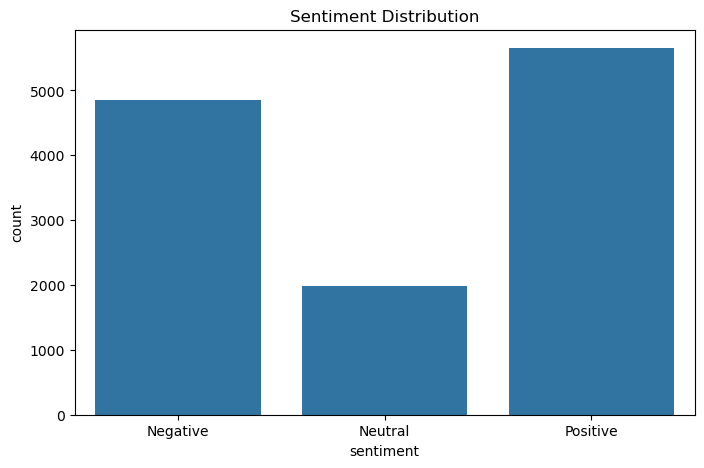

In [8]:


plt.figure(figsize=(8, 5))
sns.countplot(x='sentiment', data=df)
plt.title("Sentiment Distribution")
plt.savefig("sentiment_distribution.png")
plt.show()



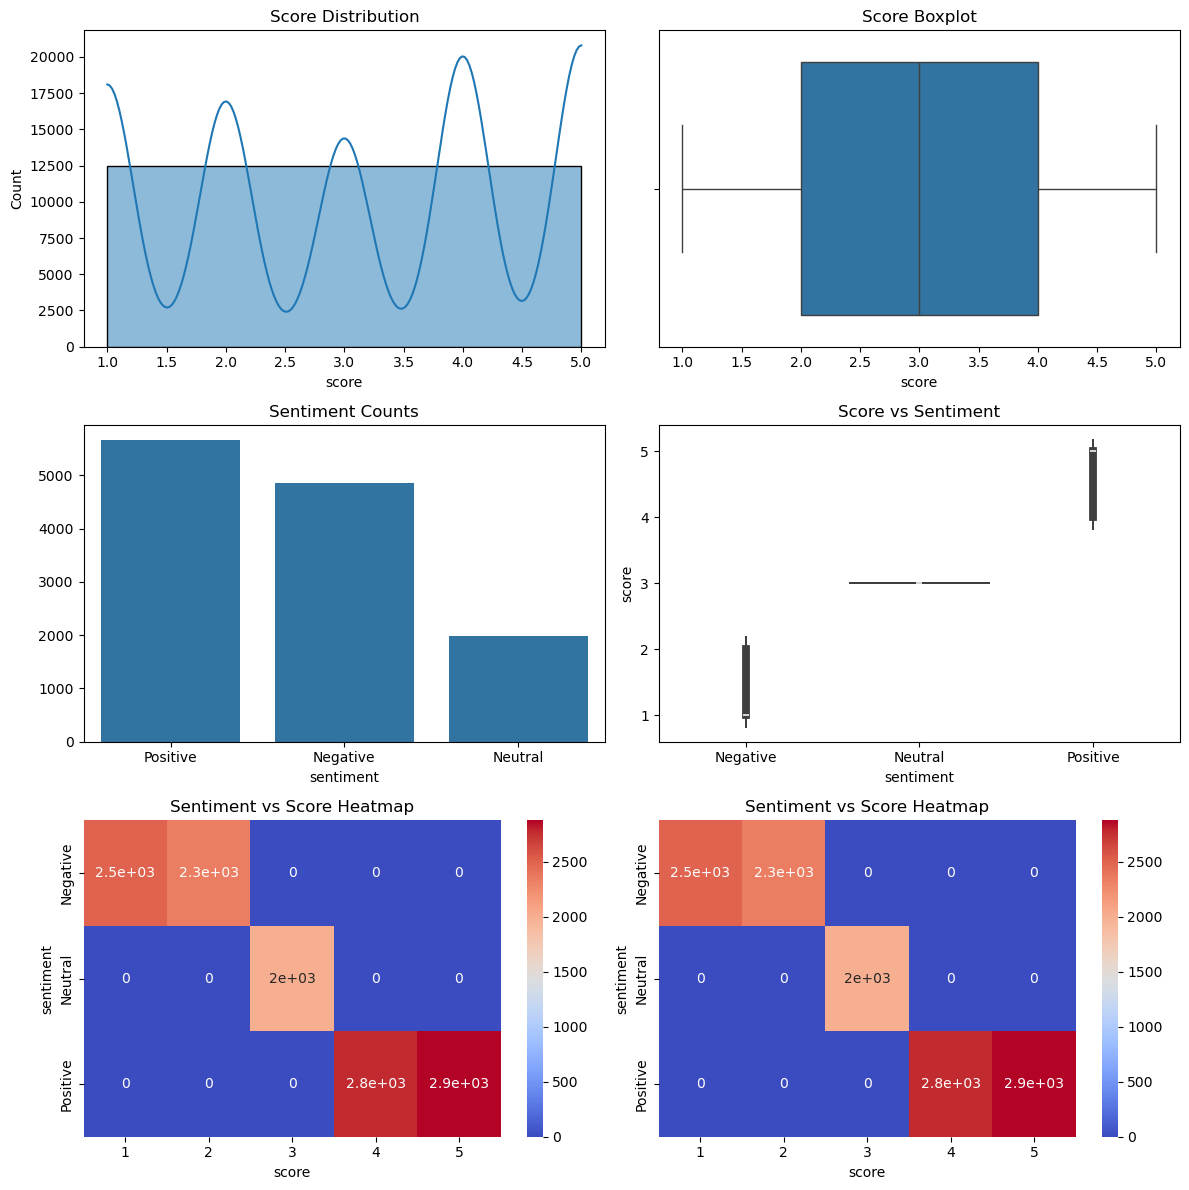

In [9]:

fig, axes = plt.subplots(3, 2, figsize=(12, 12))
sns.histplot(df['score'], bins=1, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Score Distribution")

sns.boxplot(x=df['score'], ax=axes[0, 1])
axes[0, 1].set_title("Score Boxplot")

sns.barplot(x=df['sentiment'].value_counts().index, y=df['sentiment'].value_counts().values, ax=axes[1, 0])
axes[1, 0].set_title("Sentiment Counts")

sns.violinplot(x=df['sentiment'], y=df['score'], ax=axes[1, 1])
axes[1, 1].set_title("Score vs Sentiment")

sns.heatmap(pd.crosstab(df['sentiment'], df['score']), annot=True, cmap='coolwarm', ax=axes[2, 0])
axes[2, 0].set_title("Sentiment vs Score Heatmap")
sns.heatmap(pd.crosstab(df['sentiment'], df['score']), annot=True, cmap='coolwarm', ax=axes[2, 1])
axes[2, 1].set_title("Sentiment vs Score Heatmap")
plt.tight_layout()
plt.savefig("data_visualizations.png")
plt.show()



# ML MODELS

In [10]:

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


# RF MODEL

In [ ]:

models = {
    "RandomForest": RandomForestClassifier(n_estimators=200, random_state=42),
 
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"{name} Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print(classification_report(y_test, y_pred))
    with open(f"{name}_model.pkl", "wb") as f:
        pickle.dump(model, f)

RandomForest Accuracy: 0.6947
              precision    recall  f1-score   support

    Negative       0.65      0.83      0.73       958
     Neutral       0.46      0.03      0.05       421
    Positive       0.74      0.83      0.79      1120

    accuracy                           0.69      2499
   macro avg       0.62      0.56      0.52      2499
weighted avg       0.66      0.69      0.64      2499



# DT MODEL

In [12]:

models = {
    "DecisionTree": DecisionTreeClassifier(max_depth=20, random_state=42),
 
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"{name} Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print(classification_report(y_test, y_pred))
    with open(f"{name}_model.pkl", "wb") as f:
        pickle.dump(model, f)

DecisionTree Accuracy: 0.6038
              precision    recall  f1-score   support

    Negative       0.54      0.87      0.67       958
     Neutral       0.20      0.03      0.05       421
    Positive       0.75      0.59      0.66      1120

    accuracy                           0.60      2499
   macro avg       0.50      0.50      0.46      2499
weighted avg       0.58      0.60      0.56      2499



# MLP MODEL

In [13]:
models = {
    "MLP": MLPClassifier(hidden_layer_sizes=(100,50), max_iter=500, random_state=42)
 
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"{name} Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print(classification_report(y_test, y_pred))
    with open(f"{name}_model.pkl", "wb") as f:
        pickle.dump(model, f)
    


MLP Accuracy: 0.6463
              precision    recall  f1-score   support

    Negative       0.69      0.66      0.68       958
     Neutral       0.27      0.22      0.24       421
    Positive       0.72      0.79      0.75      1120

    accuracy                           0.65      2499
   macro avg       0.56      0.56      0.56      2499
weighted avg       0.63      0.65      0.64      2499

